## MULTIPLE LINEAR REGRESSION

In [1]:
## Importing the required libraries and loading the data 
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\Multiple Linear Regression\ToyotaCorolla - MLR.csv")
df

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170
...,...,...,...,...,...,...,...,...,...,...,...
1431,7500,69,20544,Petrol,86,0,1300,3,4,5,1025
1432,10845,72,19000,Petrol,86,0,1300,3,4,5,1015
1433,8500,71,17016,Petrol,86,0,1300,3,4,5,1015
1434,7250,70,16916,Petrol,86,0,1300,3,4,5,1015


#### Observations 
* Here the Price is the target variable ie we are trying to predict it
* Age is in years KM is the the odometer reading Fuel_type is a categorical column
* HP is the horse power, Automatic is a boolean type column where 1 is true and 0 is false
* cc is the engine cylinder volume , Doors is the number of doors
* Cylinders is the No. of cylinder in the engine, Gears is the No. of gears in the transmission
* Weight is the tota weight of the car

### Exploratory Data Analysis 

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      1436 non-null   int64 
 1   Age_08_04  1436 non-null   int64 
 2   KM         1436 non-null   int64 
 3   Fuel_Type  1436 non-null   object
 4   HP         1436 non-null   int64 
 5   Automatic  1436 non-null   int64 
 6   cc         1436 non-null   int64 
 7   Doors      1436 non-null   int64 
 8   Cylinders  1436 non-null   int64 
 9   Gears      1436 non-null   int64 
 10  Weight     1436 non-null   int64 
dtypes: int64(10), object(1)
memory usage: 123.5+ KB


In [4]:
## no null values are present in the data set 
df.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


In [5]:
df.duplicated().sum()

np.int64(1)

In [6]:
# one duplicated row lets drop it 
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

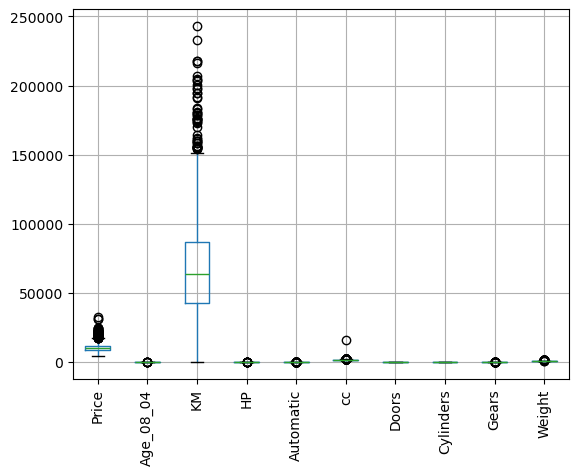

In [7]:
## Checking for outliers 
df.boxplot()
plt.xticks(rotation = 90)
plt.show()

In [8]:
### Checking Value counts of categorical columns 
df['Automatic'].value_counts()


Automatic
0    1355
1      80
Name: count, dtype: int64

In [9]:
df['Fuel_Type'].value_counts()

Fuel_Type
Petrol    1264
Diesel     154
CNG         17
Name: count, dtype: int64

In [10]:
##All the categorical data is well categorised and does not require changing 

In [11]:
## Detection and handling of outliers 
## first we make an user defined function for outlier detection 
def outlier_detection(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    IQR = q3 - q1 
    upper_extreme = q3 + (IQR * 1.5)
    lower_extreme = q1 - (IQR * 1.5)

    return column , upper_extreme , lower_extreme , q1 , q3

In [12]:
numerical_colms = ["Price","Age_08_04",	"KM", "HP",	"cc", "Doors", "Cylinders",	"Gears", "Weight" ]
for col in numerical_colms:
    print(outlier_detection(df , col))

('Price', np.float64(17200.0), np.float64(3200.0), np.float64(8450.0), np.float64(11950.0))
('Age_08_04', np.float64(109.0), np.float64(5.0), np.float64(44.0), np.float64(70.0))
('KM', np.float64(153103.75), np.float64(-23062.25), np.float64(43000.0), np.float64(87041.5))
('HP', np.float64(140.0), np.float64(60.0), np.float64(90.0), np.float64(110.0))
('cc', np.float64(1900.0), np.float64(1100.0), np.float64(1400.0), np.float64(1600.0))
('Doors', np.float64(8.0), np.float64(0.0), np.float64(3.0), np.float64(5.0))
('Cylinders', np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0))
('Gears', np.float64(5.0), np.float64(5.0), np.float64(5.0), np.float64(5.0))
('Weight', np.float64(1152.5), np.float64(972.5), np.float64(1040.0), np.float64(1085.0))


In [13]:
## now replacing the outliers with lower and upper extremes 
def outlier_handling(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    IQR = q3 - q1 
    upper_extreme = q3 + (IQR * 1.5)
    lower_extreme = q1 - (IQR * 1.5)

    data[column] = data[column].clip(lower_extreme, upper_extreme)

In [14]:
## using a loop 
numerical_colms = ["Age_08_04",	"KM", "HP",	"cc", "Doors", "Cylinders",	"Gears", "Weight" ] #ignoring the price since its our target variable
for col in numerical_colms:
    outlier_handling(df , col) 

C:\Users\deytu\AppData\Local\Temp\ipykernel_24180\3501539825.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[column] = data[column].clip(lower_extreme, upper_extreme)
C:\Users\deytu\AppData\Local\Temp\ipykernel_24180\3501539825.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[column] = data[column].clip(lower_extreme, upper_extreme)
C:\Users\deytu\AppData\Local\Temp\ipykernel_24180\3501539825.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

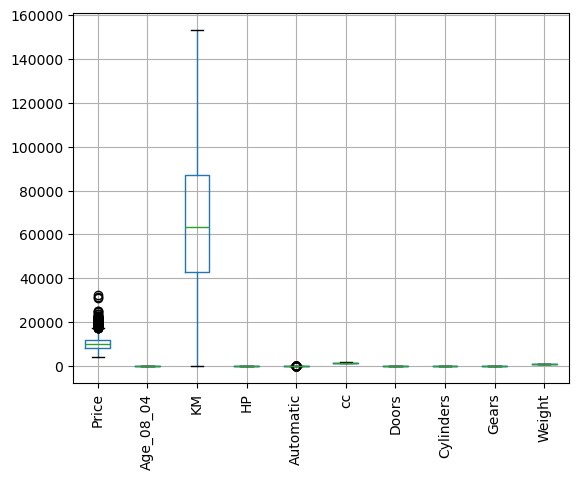

In [15]:
df.boxplot()
plt.xticks(rotation = 90)
plt.show()

### Observations
* all the outliers has been handled besides our target variable and categorical columns
* After capping, the whiskers now extend to the capped boundary values, and the extreme points have disappeared.
* This is exactly what we expect after applying IQR-based capping (Winsorization).

### Statistical analysis 

In [16]:
numerical_colms = ["Price","Age_08_04",	"KM", "HP",	"cc", "Doors", "Cylinders",	"Gears", "Weight" ]

In [17]:
df_stats = pd.DataFrame({
    "Mean": df[numerical_colms].mean(),
    "Median": df[numerical_colms].median(),
    "mode": df[numerical_colms].mode().iloc[0],
    "Standard diviation": df[numerical_colms].std()
    })
df_stats

,Mean,Median,mode,Standard diviation
Price,10720.915679,9900.0,8950.00,3608.732978
Age_08_04,55.992334,61.0,68.00,18.529725
KM,67644.520383,63451.0,153103.75,34725.393258
HP,101.093380,110.0,110.00,13.146145
cc,1558.327526,1600.0,1600.00,168.788311
Doors,4.032753,4.0,5.00,0.952667
Cylinders,4.000000,4.0,4.00,0.000000
Gears,5.000000,5.0,5.00,0.000000
Weight,1068.520906,1070.0,1075.00,37.722708


### Observations
* Price and KM are slightly right-skewed (Mean > Median).
* Age, HP, cc, and Weight are nearly symmetric (Mean ≈ Median).
* Outlier treatment reduced extreme values, resulting in reasonable variability.
* Cylinders and Gears have no variation (SD = 0) and can be dropped.

In [18]:
### Checking if gears and cylinders have only one value
df["Gears"].value_counts()

Gears
5    1435
Name: count, dtype: int64

In [19]:
df["Cylinders"].value_counts()

Cylinders
4    1435
Name: count, dtype: int64

In [20]:
## hence we can drop these columns further in our analysis to build a model since they do not contribute
df.drop(columns = ["Gears","Cylinders"] , inplace = True)

C:\Users\deytu\AppData\Local\Temp\ipykernel_24180\228548804.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns = ["Gears","Cylinders"] , inplace = True)


In [21]:
df

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Weight
0,13500,23,46986.0,Diesel,90,0,1900,3,1152.5
1,13750,23,72937.0,Diesel,90,0,1900,3,1152.5
2,13950,24,41711.0,Diesel,90,0,1900,3,1152.5
3,14950,26,48000.0,Diesel,90,0,1900,3,1152.5
4,13750,30,38500.0,Diesel,90,0,1900,3,1152.5
...,...,...,...,...,...,...,...,...,...
1431,7500,69,20544.0,Petrol,86,0,1300,3,1025.0
1432,10845,72,19000.0,Petrol,86,0,1300,3,1015.0
1433,8500,71,17016.0,Petrol,86,0,1300,3,1015.0
1434,7250,70,16916.0,Petrol,86,0,1300,3,1015.0


In [22]:
##Handling of categorical data 
df = pd.get_dummies(df, columns=['Fuel_Type'], drop_first=True)
df

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Weight,Fuel_Type_Diesel,Fuel_Type_Petrol
0,13500,23,46986.0,90,0,1900,3,1152.5,True,False
1,13750,23,72937.0,90,0,1900,3,1152.5,True,False
2,13950,24,41711.0,90,0,1900,3,1152.5,True,False
3,14950,26,48000.0,90,0,1900,3,1152.5,True,False
4,13750,30,38500.0,90,0,1900,3,1152.5,True,False
...,...,...,...,...,...,...,...,...,...,...
1431,7500,69,20544.0,86,0,1300,3,1025.0,False,True
1432,10845,72,19000.0,86,0,1300,3,1015.0,False,True
1433,8500,71,17016.0,86,0,1300,3,1015.0,False,True
1434,7250,70,16916.0,86,0,1300,3,1015.0,False,True


In [23]:
### Deleting one feul type dummy 
df.drop(columns=['Fuel_Type_Diesel'], inplace = True)

### Data Visualisation

In [24]:
df

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Weight,Fuel_Type_Petrol
0,13500,23,46986.0,90,0,1900,3,1152.5,False
1,13750,23,72937.0,90,0,1900,3,1152.5,False
2,13950,24,41711.0,90,0,1900,3,1152.5,False
3,14950,26,48000.0,90,0,1900,3,1152.5,False
4,13750,30,38500.0,90,0,1900,3,1152.5,False
...,...,...,...,...,...,...,...,...,...
1431,7500,69,20544.0,86,0,1300,3,1025.0,True
1432,10845,72,19000.0,86,0,1300,3,1015.0,True
1433,8500,71,17016.0,86,0,1300,3,1015.0,True
1434,7250,70,16916.0,86,0,1300,3,1015.0,True


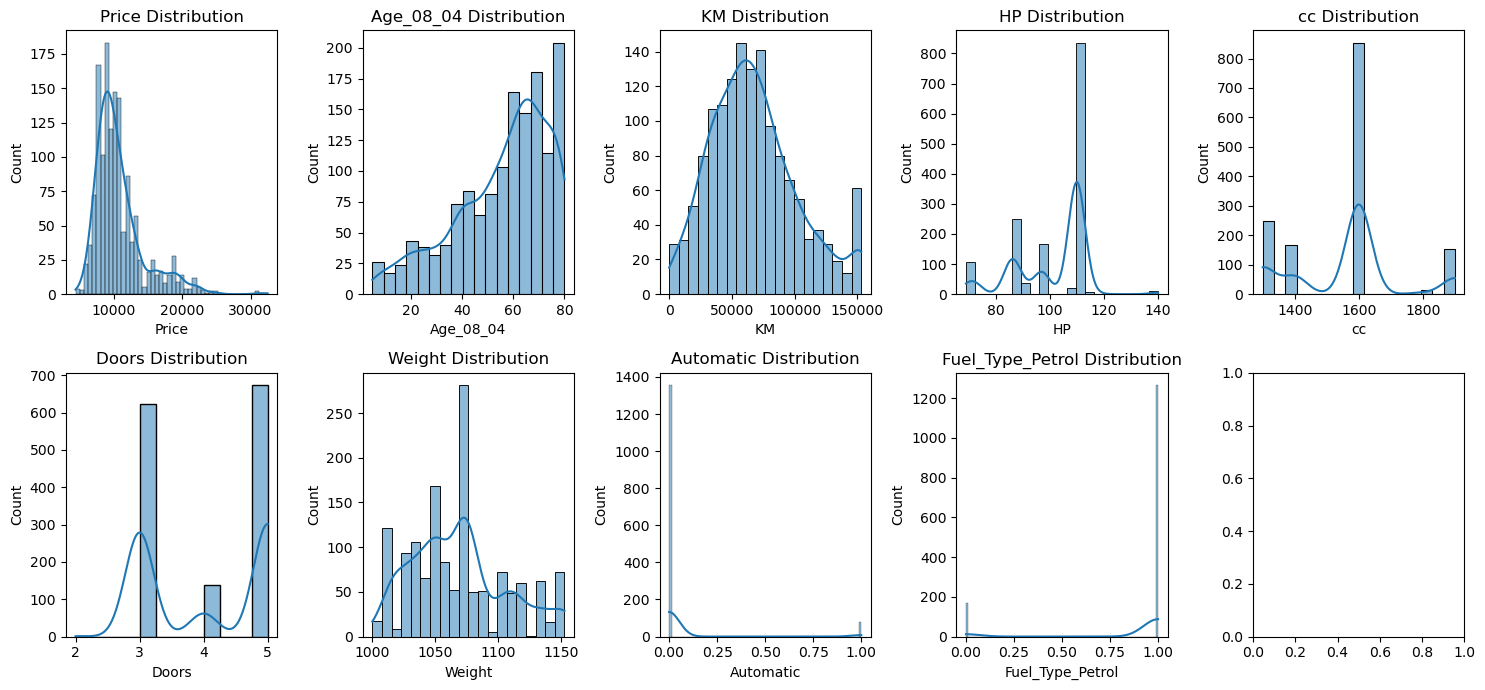

In [25]:
## Histogram 
numerical_cols = ["Price","Age_08_04",	"KM", "HP",	"cc", "Doors", "Weight","Automatic","Fuel_Type_Petrol"]
fig, axes = plt.subplots(2,5, figsize=(15,7))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.histplot(data = df , x =col , kde = True , ax = axes[i])
    axes[i].set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

### Observations
* Price is positively skewed, with most cars priced between ₹8,000–₹12,000 and a few high-priced cars creating a right tail.
* Age_08_04 shows a negative skew, indicating that a larger proportion of cars are older rather than newer.
* KM follows an approximately bell-shaped distribution, with most cars having mileage between 40,000 and 90,000 km.
* HP, cc, and Doors are discrete variables, showing distinct peaks at specific values (e.g., HP around 110, cc around 1600, and Doors around 3 and 5).
* Weight is fairly symmetric, with most vehicles weighing between 1030 and 1100 kg.
* No extreme outliers are visible, suggesting that the outlier treatment was effective in reducing unusually large or small values.

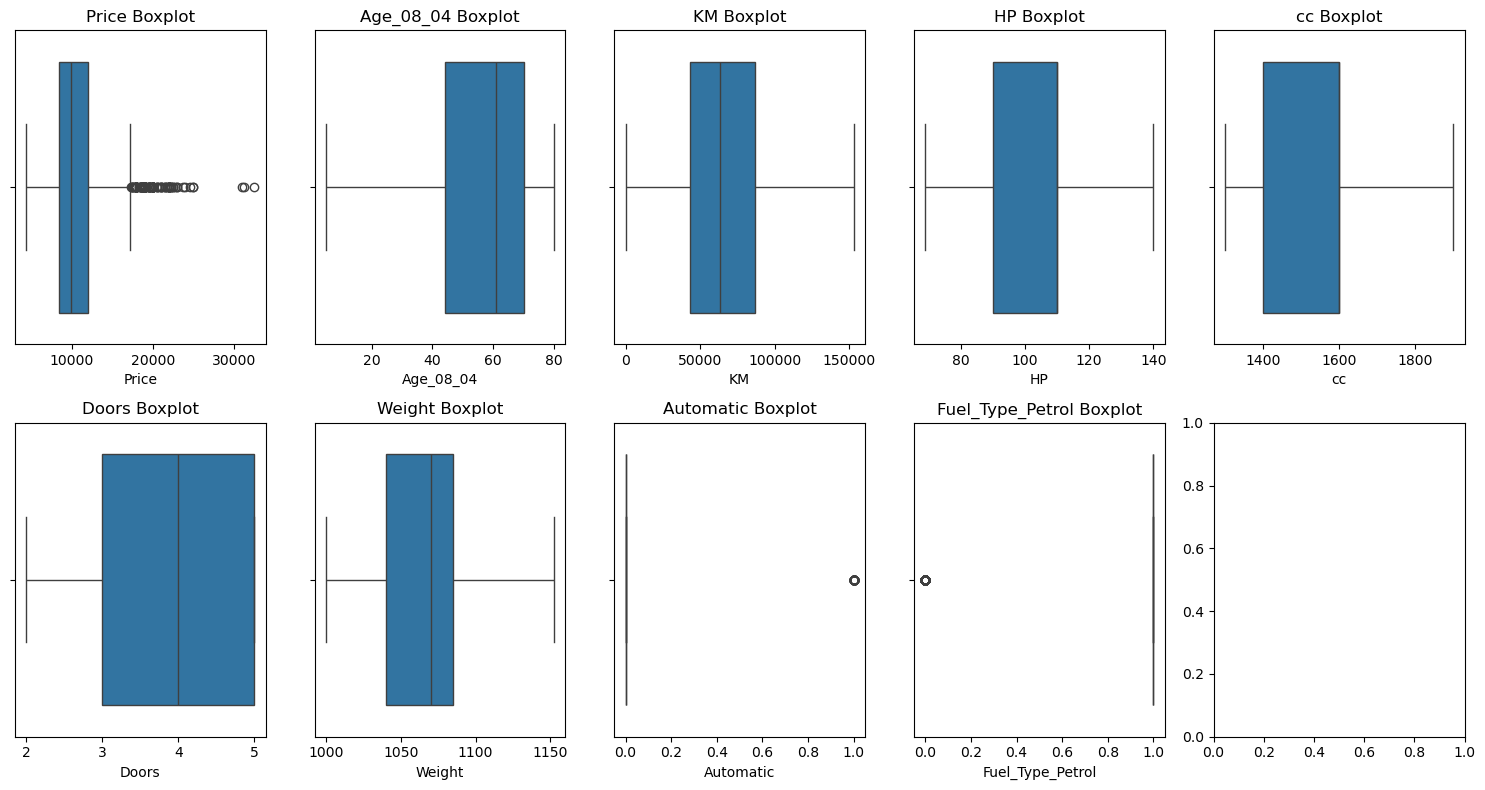

In [26]:
columns=["Price","Age_08_04",	"KM", "HP",	"cc", "Doors", "Weight","Automatic","Fuel_Type_Petrol"]
fig, axes = plt.subplots(2,5 ,figsize=(15,8))
axes = axes.flatten()
for i, col in enumerate(columns):
    sns.boxplot(data = df , x=col , ax = axes[i])
    axes[i].set_title(f"{col} Boxplot")

plt.tight_layout()
plt.show()

* outliers are absent besides the categorical and target variable column
* the categorical plots are a single line meaning most observation are concentrated there

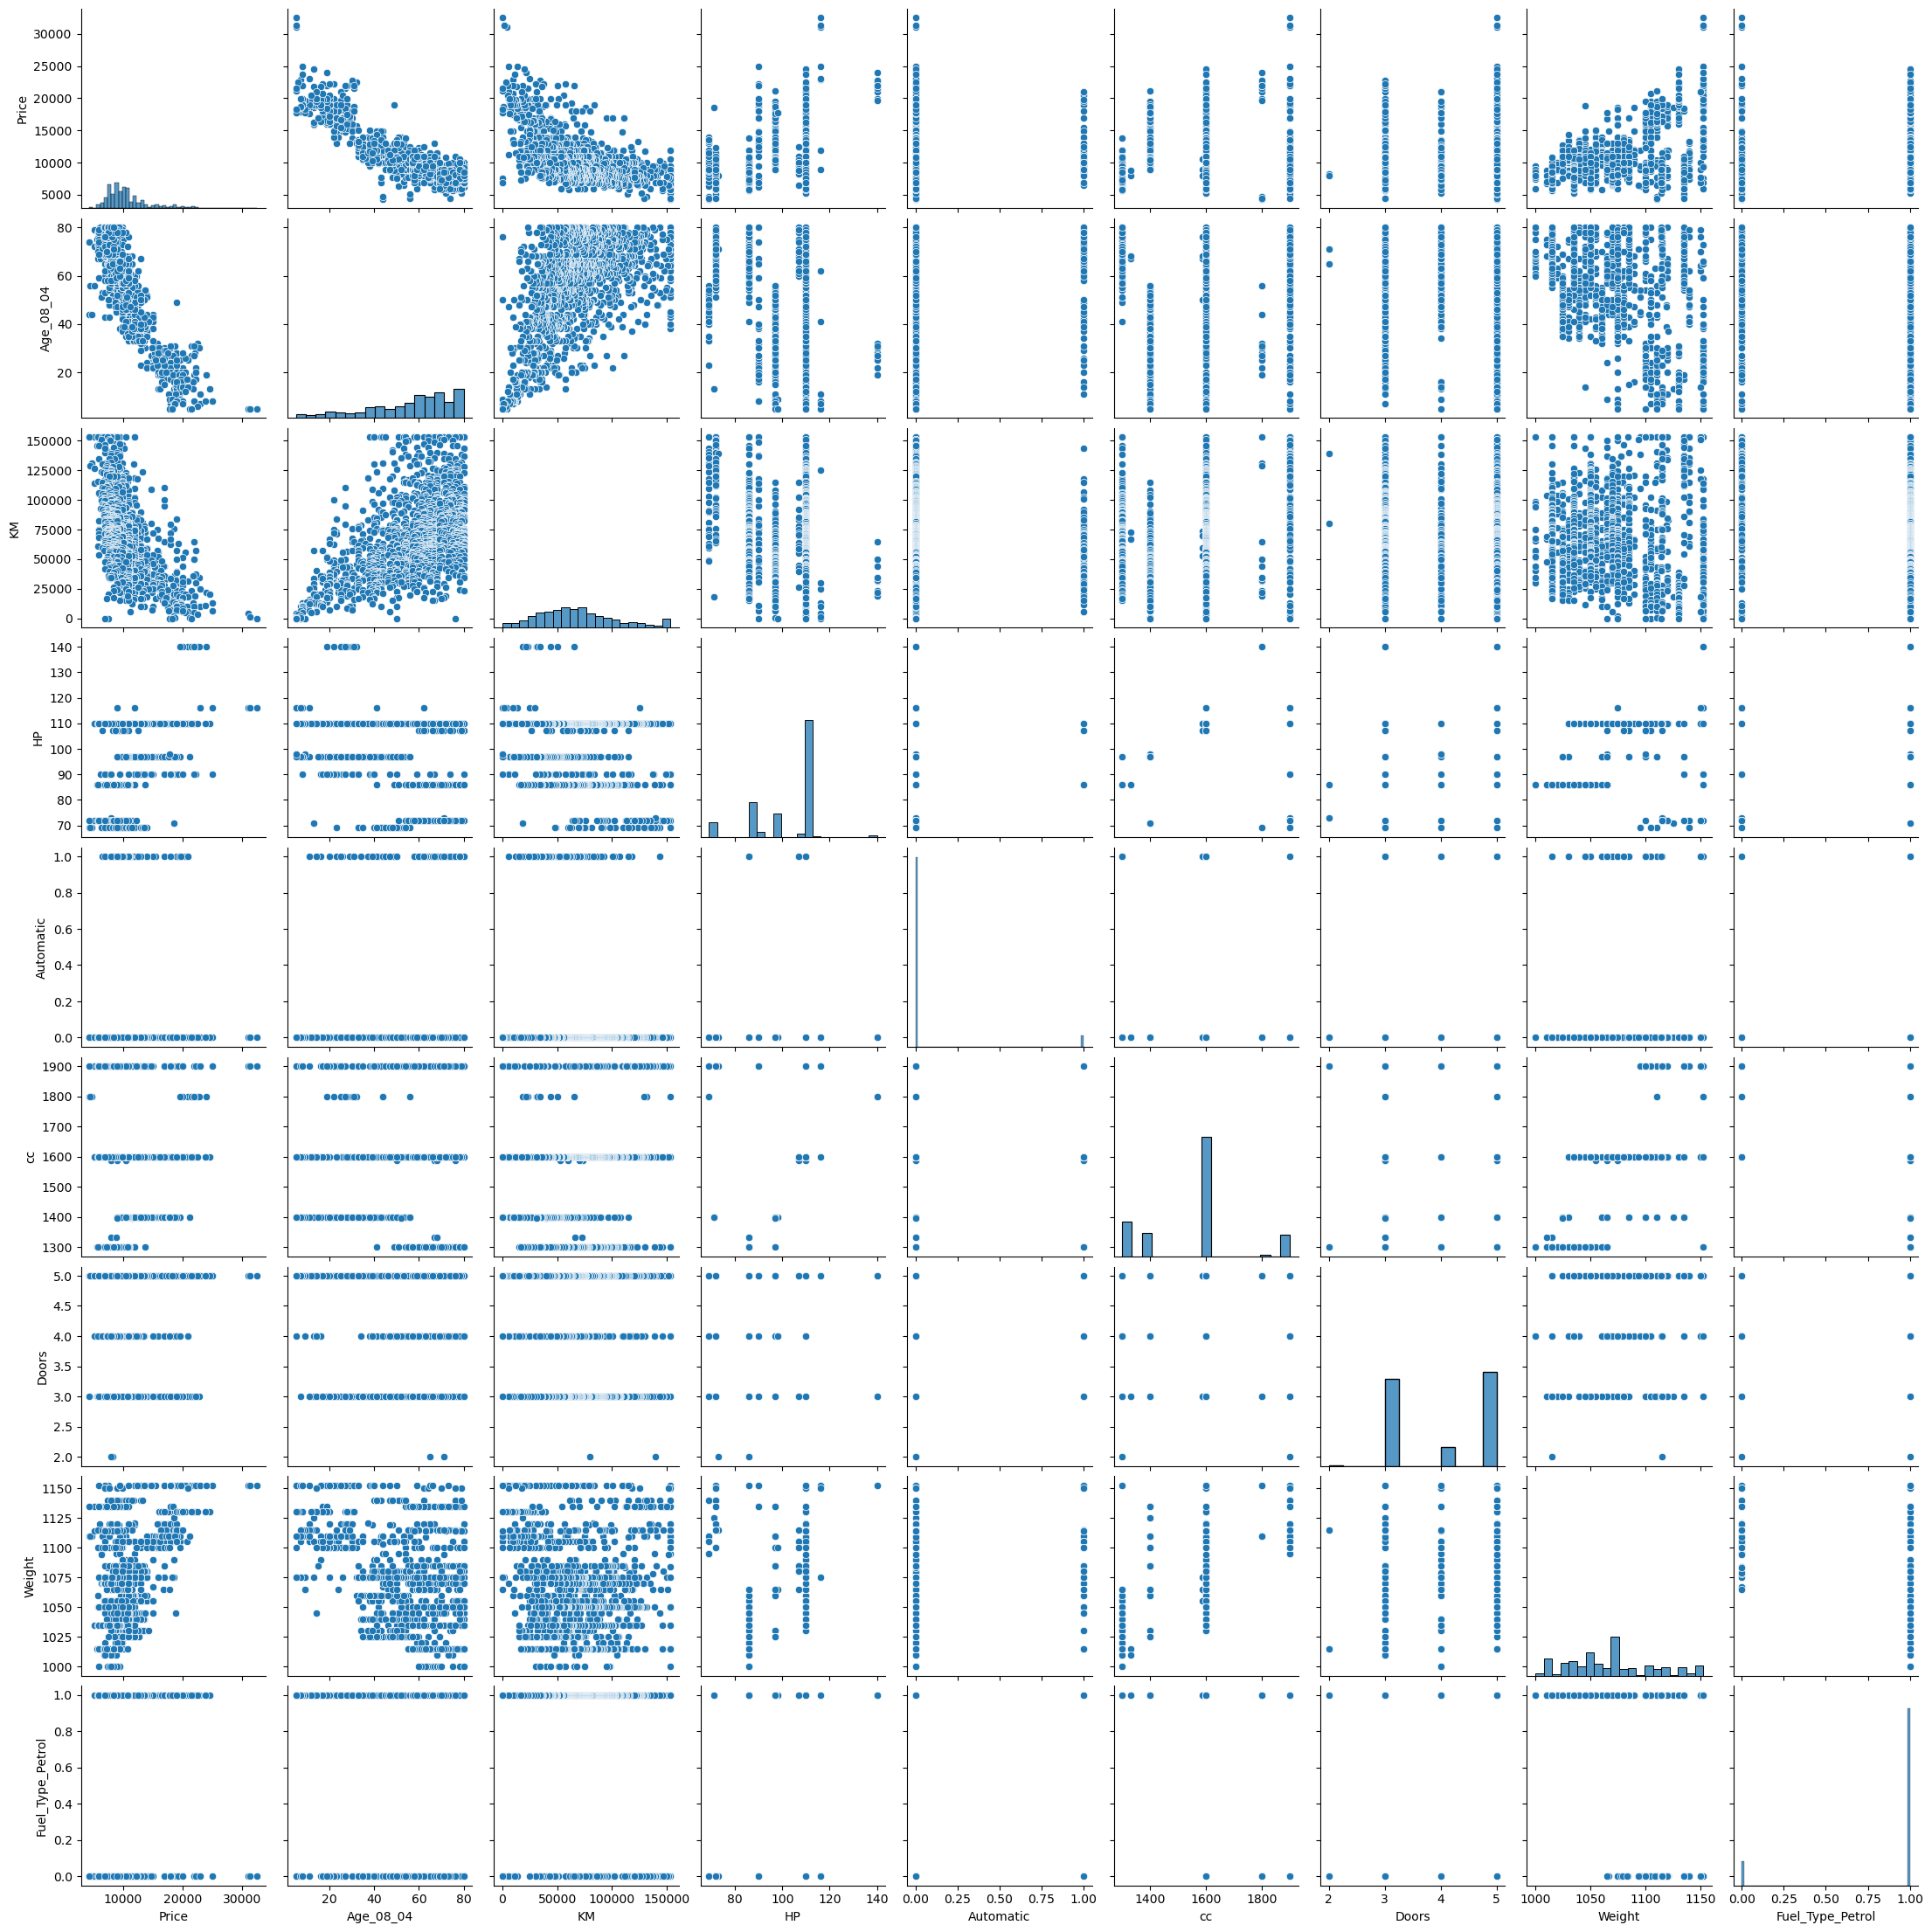

In [27]:
## Using Pair plot 
sns.pairplot(df)
plt.show()

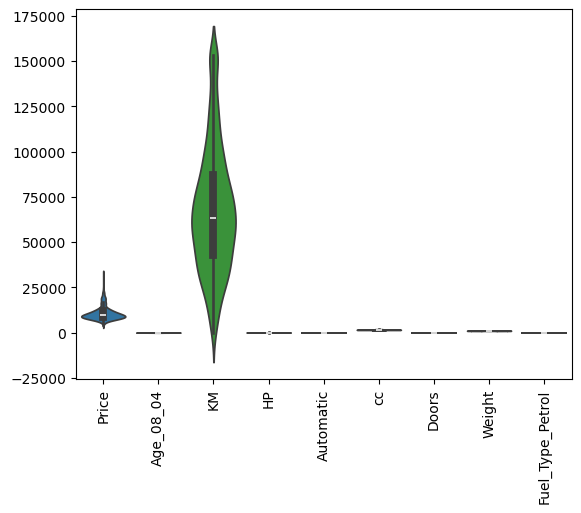

In [28]:
sns.violinplot(df)
plt.xticks(rotation = 90)
plt.show()

#### Observations 
* only KM and Price are distributed with a large range rest all are concentrated
* since KM has a large spread and has high upper limit we should apply standardization

In [29]:
## correlation 
df.corr()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Weight,Fuel_Type_Petrol
Price,1.000000,-0.875937,-0.586871,0.265753,0.033928,0.168424,0.183604,0.534909,-0.031356
Age_08_04,-0.875937,1.000000,0.530670,-0.129602,0.031255,-0.136644,-0.146704,-0.476150,0.088216
KM,-0.586871,0.530670,1.000000,-0.329729,-0.082221,0.258680,-0.036618,0.000977,-0.408052
HP,0.265753,-0.129602,-0.329729,1.000000,0.022541,0.098192,0.120139,0.024877,0.549942
Automatic,0.033928,0.031255,-0.082221,0.022541,1.000000,-0.059263,-0.027492,0.090598,0.079997
cc,0.168424,-0.136644,0.258680,0.098192,-0.059263,1.000000,0.138433,0.717782,-0.675943
Doors,0.183604,-0.146704,-0.036618,0.120139,-0.027492,0.138433,1.000000,0.381177,-0.025746
Weight,0.534909,-0.476150,0.000977,0.024877,0.090598,0.717782,0.381177,1.000000,-0.577437
Fuel_Type_Petrol,-0.031356,0.088216,-0.408052,0.549942,0.079997,-0.675943,-0.025746,-0.577437,1.000000


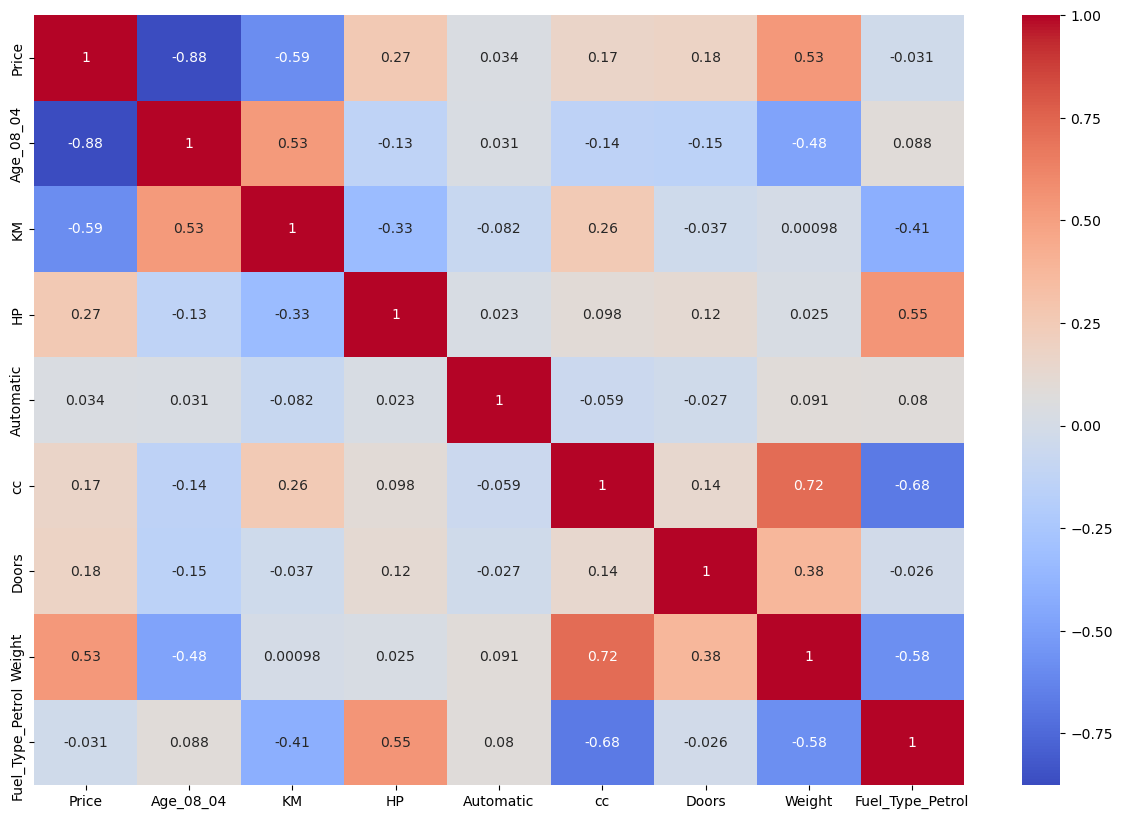

In [30]:
plt.figure(figsize = (15,10))
sns.heatmap(df.corr(numeric_only = True) , annot = True , cmap = "coolwarm" )
plt.show()

### Observations 
* Age_08_04 has the strongest negative correlation with Price (-0.876), indicating older cars tend to have lower prices.
* KM also shows a strong negative relationship with Price (-0.587), meaning higher mileage reduces car value.
* Weight has a moderate positive correlation with Price (0.535), suggesting heavier cars are generally more expensive.
* Fuel_Type and Automatic have weak correlations with Price, but should be evaluated further using regression p-values before removal.

## Splitting data
Splitting data into 80% training 20% testing for further evaluation

In [31]:
from sklearn.model_selection import train_test_split

In [32]:
# Features and target
X = df.drop("Price", axis=1)
y = df["Price"]

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (1148, 8)
Testing set shape: (287, 8)


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error, mean_squared_error
mlr = LinearRegression() 
mlr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:
y_pred = mlr.predict(X_test)

In [35]:
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test , y_pred)
mae = mean_absolute_error(y_test , y_pred)
print("r2 score = ",r2)
print("MSE score = ",mse)
print("MAE score = ",mae)

r2 score =  0.8199316941437991
MSE score =  2160303.5534195644
MAE score =  1041.2650222472178


In [36]:
X["Fuel_Type_Petrol"] = X["Fuel_Type_Petrol"].astype(int) ### Converting the Fuel_type_Petrol to integer to avoid conflits during summary 

In [37]:
import statsmodels.api as sm
def fit_mlr(A,b):
    X_const = sm.add_constant(A)

    model = sm.OLS(b, X_const).fit()

    print(model.summary())

In [38]:
fit_mlr(X,y)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.842
Model:                            OLS   Adj. R-squared:                  0.841
Method:                 Least Squares   F-statistic:                     950.2
Date:                Sat, 06 Jun 2026   Prob (F-statistic):               0.00
Time:                        04:50:34   Log-Likelihood:                -12466.
No. Observations:                1435   AIC:                         2.495e+04
Df Residuals:                    1426   BIC:                         2.500e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -1.24e+04   2017.760  

In [39]:
X = X.drop("Automatic", axis=1) ### we drop the Automatic column since it has a p value of .981 suggesting it is insignificant

In [48]:
fit_mlr(X,y)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.842
Model:                            OLS   Adj. R-squared:                  0.841
Method:                 Least Squares   F-statistic:                     1087.
Date:                Sat, 06 Jun 2026   Prob (F-statistic):               0.00
Time:                        04:51:18   Log-Likelihood:                -12466.
No. Observations:                1435   AIC:                         2.495e+04
Df Residuals:                    1427   BIC:                         2.499e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.238e+04   1931.978  

### Observations
* After removing the insignificant variable Automatic, the model retained an R² of 0.842.
* All remaining predictors were statistically significant at the 5% significance level.
* The model explains approximately 84.2% of the variation in car prices.
* Although multicollinearity is still present, the retained variables contribute significantly to the model and were kept for further analysis.

### Multicolinearity 
Checking for multicolinearity 

In [41]:
X_vif = X.copy()


print(X_vif.dtypes)

Age_08_04             int64
KM                  float64
HP                    int64
cc                    int64
Doors                 int64
Weight              float64
Fuel_Type_Petrol      int64
dtype: object


In [42]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
def calculate_vif(data):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = data.columns
    vif_data["VIF"] = [variance_inflation_factor(data.to_numpy(dtype=float), i)
                   for i in range(data.shape[1])]

    print(vif_data)

In [43]:
calculate_vif(X_vif)

            Feature         VIF
0         Age_08_04   17.167936
1                KM    9.489232
2                HP  213.164715
3                cc  453.440342
4             Doors   21.276754
5            Weight  347.639038
6  Fuel_Type_Petrol   49.020196


In [44]:
#### high multicolinearity is present we start by dropping the column with the highest VIF which is cc
X_vif.drop(columns=["cc"], inplace = True) 

In [45]:
## re Checking the vif
calculate_vif(X_vif)

            Feature         VIF
0         Age_08_04   16.711542
1                KM    9.420341
2                HP  105.148448
3             Doors   21.160295
4            Weight  103.495653
5  Fuel_Type_Petrol   17.229648


In [46]:
## Now the VIFs are far better but their is still high multicolinearity now since Weight had a higher correlation with Price we will eliminate HP and recalculate
X_vif = X_vif.drop("HP", axis=1)

In [47]:
calculate_vif(X_vif)

            Feature        VIF
0         Age_08_04  16.589812
1                KM   9.414522
2             Doors  21.146502
3            Weight  37.893611
4  Fuel_Type_Petrol  10.876597


In [50]:
### Since the Multicolinearity is now more acceptable besides weight we try and fit the model and calculate the summary
X = X_vif
fit_mlr(X,y)

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.833
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     1429.
Date:                Sat, 06 Jun 2026   Prob (F-statistic):               0.00
Time:                        04:53:28   Log-Likelihood:                -12504.
No. Observations:                1435   AIC:                         2.502e+04
Df Residuals:                    1429   BIC:                         2.505e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.438e+04   1867.193  

### Conclusion to MLR 
* The final MLR model explains 83.3% of the variation in car prices.
* All retained predictors are statistically significant at the 5% level.
* Variables causing severe multicollinearity (cc and HP) were removed through iterative refinement.
* The final model is simpler, more interpretable, and maintains strong predictive performance.
##### Final Model 
Price = − 14380.67 − 123.35(Age_08_04) − 0.0209(KM) − 134.16(Doors) + 30.62(Weight) + 1408.74(Fuel_Type_Petrol)

### Standardization
Since the above mlr model didnt require us to standardize the data but for Ridge and Lasso its very much required 

In [58]:
from sklearn.preprocessing import StandardScaler

scale = StandardScaler()
X_train_scaled = scale.fit_transform(X_train)
X_test_scaled = scale.fit_transform(X_test)

In [62]:
## Converting Array to a Dataframe for application of Ridge and Lasso
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns
)

In [63]:
X_train_scaled


,Age_08_04,KM,HP,Automatic,cc,Doors,Weight,Fuel_Type_Petrol
0,1.188057,1.183373,0.679386,-0.234834,0.239433,1.020018,0.034384,0.371161
1,0.330804,-0.255951,-1.144668,-0.234834,-1.531177,1.020018,-0.884513,0.371161
2,0.813009,0.639162,-1.144668,-0.234834,-1.531177,1.020018,-0.884513,0.371161
3,-0.633606,-0.856072,0.679386,-0.234834,0.239433,1.020018,0.296926,0.371161
4,1.027322,0.969986,0.679386,-0.234834,0.239433,1.020018,0.034384,0.371161
...,...,...,...,...,...,...,...,...
1143,1.027322,1.648198,0.679386,-0.234834,0.239433,-1.082281,-0.490700,0.371161
1144,1.027322,1.118187,0.679386,-0.234834,0.239433,-1.082281,-0.490700,0.371161
1145,1.295214,0.095613,0.679386,-0.234834,0.239433,-0.031132,-0.884513,0.371161
1146,0.491539,-0.102277,0.679386,-0.234834,0.239433,1.020018,0.034384,0.371161


### Ridge and Lasso

In [65]:
from sklearn.linear_model import Ridge, Lasso
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)
## here alpha is regularization strength 

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [66]:
### Checking r2 scores
from sklearn.metrics import r2_score

print("Ridge R²:", r2_score(y_test, ridge.predict(X_test_scaled)))
print("Lasso R²:", r2_score(y_test, lasso.predict(X_test_scaled)))

Ridge R²: 0.818580932413832
Lasso R²: 0.8186832680377263


## Conclusion 
* Ridge R²: 0.8185
* Lasso R²: 0.8186
* MLR R²: 0.833
* Best Model: Multiple Linear Regression (slightly higher R² and easier interpretation).
* Multiple Linear Regression, Ridge Regression, and Lasso Regression were applied to predict car prices.
* The models achieved similar R² scores of approximately 0.82, indicating comparable predictive performance.
* Ridge and Lasso regularization did not significantly improve accuracy, suggesting that the model was already stable.
* Therefore, the Multiple Linear Regression model was retained due to its simplicity and interpretability.